# Bài 2 (Trang 18 – 19) – Gom cụm dữ liệu Mall Customers bằng k-Means

**Họ tên:** Mai Quốc Đại — **MSSV:** 6451071013 — **Lớp:** CQ.64.CNTT

## Câu 1) Nhập dữ liệu, thống kê cơ bản, xử lý dữ liệu thiếu

In [1]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
import pandas as pd
pd.set_option("display.width", 140)
import numpy as np
from sklearn.cluster import KMeans
from sklearn import metrics
import seaborn as sns
import plotly.graph_objects as go
import plotly.io as pio
import matplotlib.pyplot as plt
pio.renderers.default = "notebook_connected"

data = pd.read_csv("data/Mall_Customers.csv")
print("Kích thước:", data.shape)
print(data.head())
print("\nKiểu dữ liệu:"); print(data.dtypes)
print("\nThống kê mô tả:"); print(data.describe())
print("\nSố giá trị thiếu mỗi cột:"); print(data.isnull().sum())
# Xử lý dữ liệu thiếu: điền trung vị cho cột số, giá trị phổ biến nhất cho cột phân loại
for col in data.columns:
    if data[col].isnull().any():
        is_num = pd.api.types.is_numeric_dtype(data[col])
        data[col] = data[col].fillna(data[col].median() if is_num else data[col].mode()[0])
print("\nSau xử lý, tổng số giá trị thiếu:", int(data.isnull().sum().sum()))

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
Kích thước: (200, 5)
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Kiểu dữ liệu:
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

Thống kê mô tả:
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.

## Câu 2) Histogram phân phối Tuổi, Thu nhập, Điểm mua sắm

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


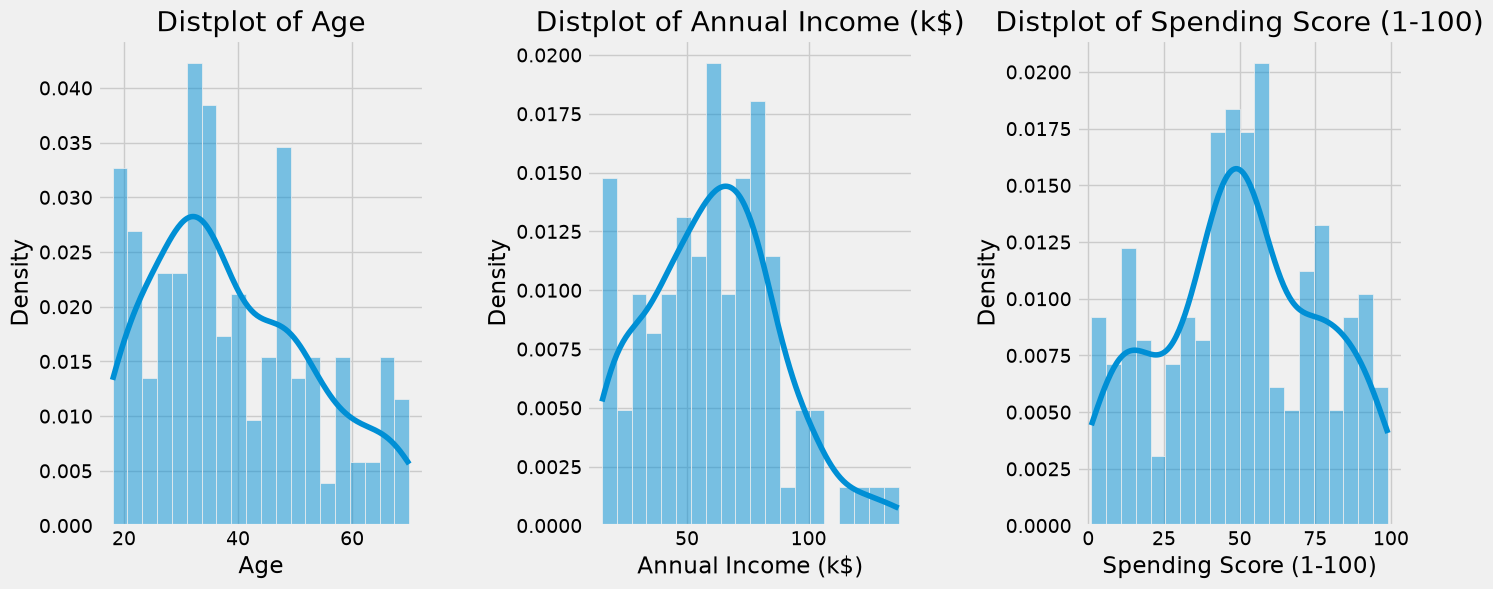

In [2]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
plt.style.use("fivethirtyeight")
plt.figure(1, figsize=(15, 6))
n = 0
for x in ["Age", "Annual Income (k$)", "Spending Score (1-100)"]:
    n += 1
    plt.subplot(1, 3, n)
    plt.subplots_adjust(hspace=0.5, wspace=0.5)
    sns.histplot(data[x], bins=20, kde=True, stat="density")
    plt.title("Distplot of {}".format(x))
plt.show()

## Câu 3) Thống kê số mẫu theo Giới tính

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
Gender
Female    112
Male       88
Name: count, dtype: int64


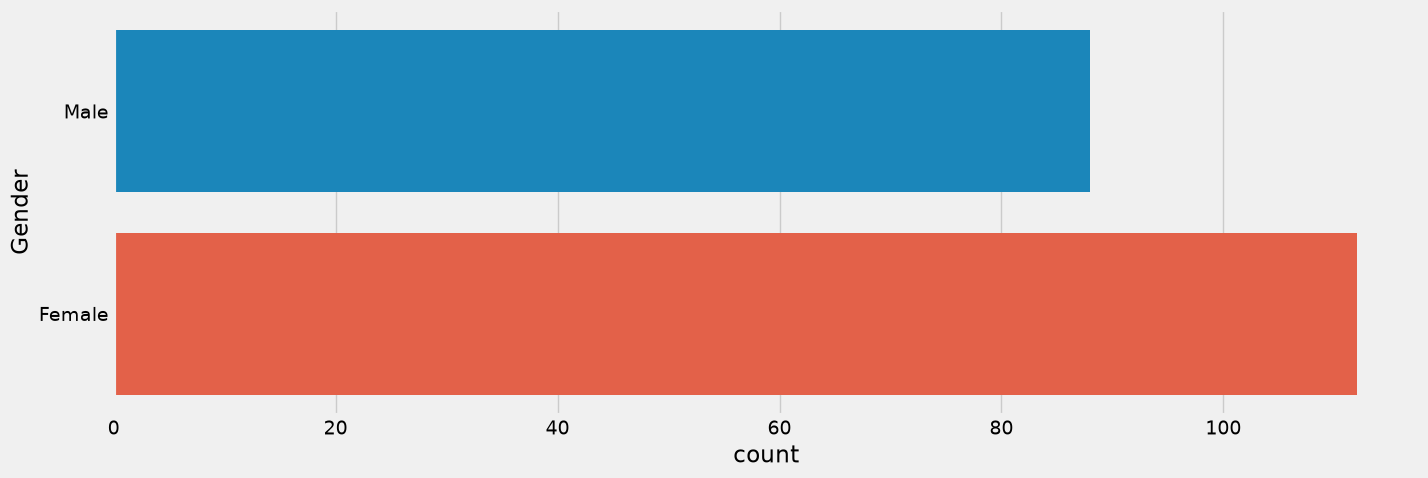

In [ ]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
print(data["Gender"].value_counts())
plt.figure(1, figsize=(15, 5))
sns.countplot(y="Gender", data=data, hue="Gender")a
plt.show()

## Câu 4) Scatter plot Tuổi – Thu nhập theo Giới tính

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


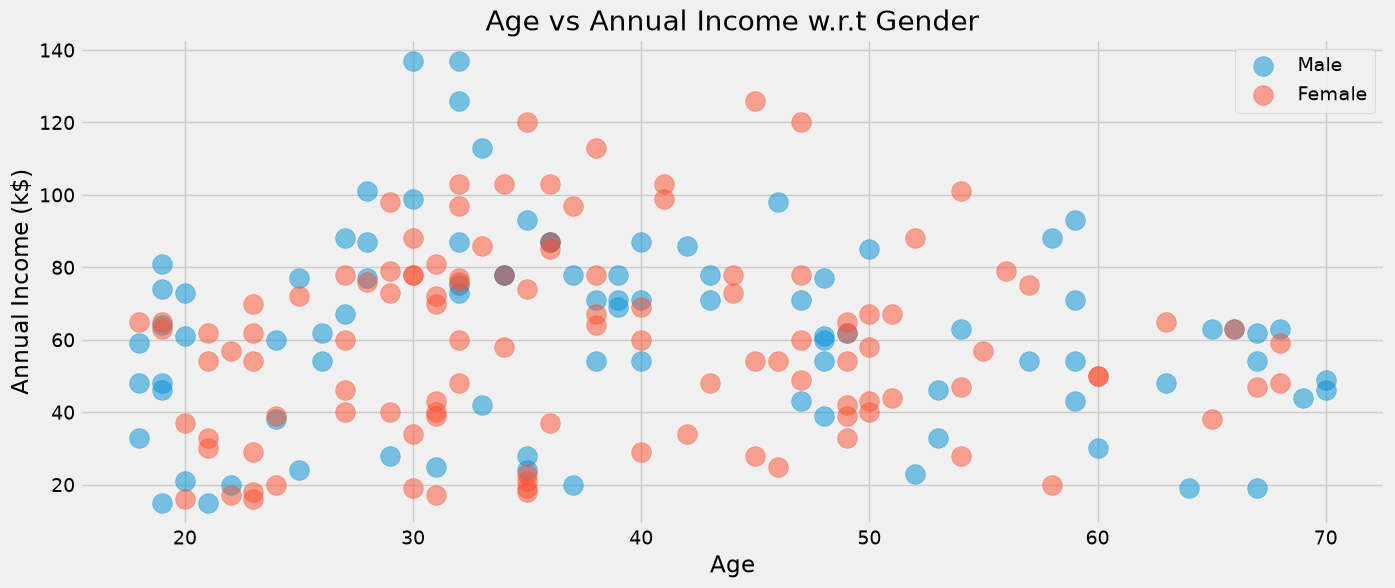

In [4]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
plt.figure(1, figsize=(15, 6))
for gender in ["Male", "Female"]:
    plt.scatter(x="Age", y="Annual Income (k$)", data=data[data["Gender"] == gender],
                s=200, alpha=0.5, label=gender)
plt.xlabel("Age"), plt.ylabel("Annual Income (k$)")
plt.title("Age vs Annual Income w.r.t Gender")
plt.legend(); plt.show()

## Câu 5) Scatter plot Thu nhập – Điểm mua sắm theo Giới tính

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


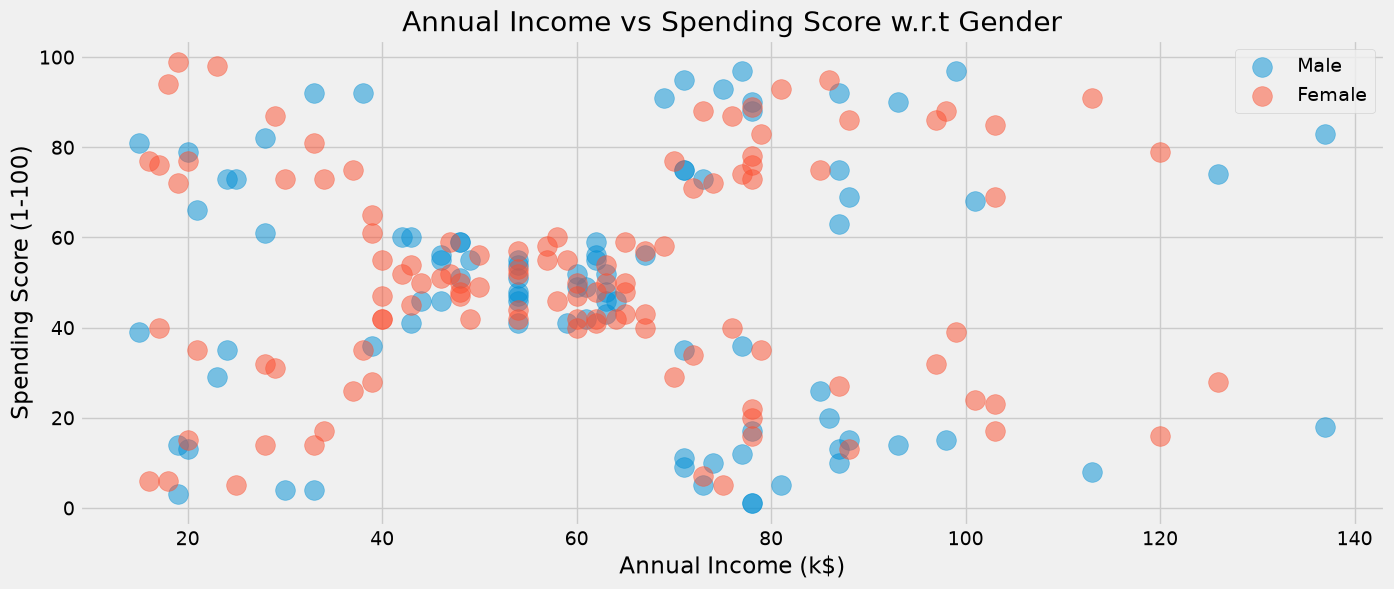

In [5]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
plt.figure(1, figsize=(15, 6))
for gender in ["Male", "Female"]:
    plt.scatter(x="Annual Income (k$)", y="Spending Score (1-100)", data=data[data["Gender"] == gender],
                s=200, alpha=0.5, label=gender)
plt.xlabel("Annual Income (k$)"), plt.ylabel("Spending Score (1-100)")
plt.title("Annual Income vs Spending Score w.r.t Gender")
plt.legend(); plt.show()

## Câu 6) Gom cụm Tuổi – Điểm mua sắm: Elbow + k-Means

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


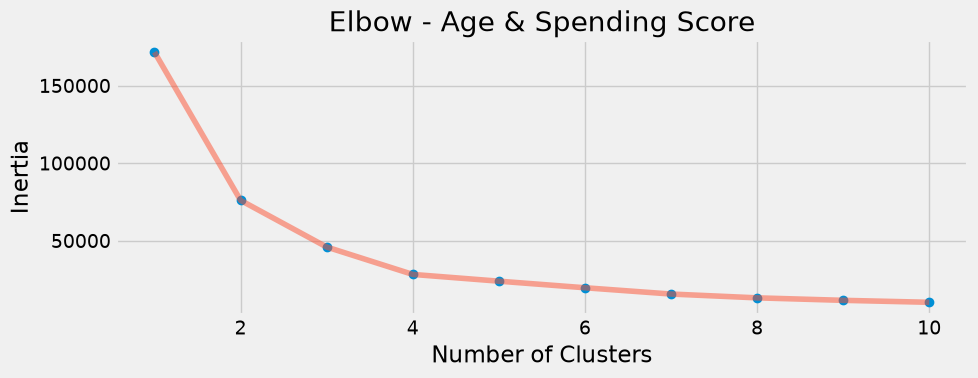

k =  1: inertia = 171,535.5
k =  2: inertia = 75,949.2
k =  3: inertia = 45,840.7
k =  4: inertia = 28,165.6
k =  5: inertia = 23,811.5
k =  6: inertia = 19,566.5
k =  7: inertia = 15,514.2
k =  8: inertia = 13,055.6
k =  9: inertia = 11,453.3
k = 10: inertia = 10,186.5


In [6]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
def elbow(X, title):
    inertia = []
    for n in range(1, 11):
        algorithm = KMeans(n_clusters=n, init="k-means++", n_init=10, random_state=42)
        algorithm.fit(X)
        inertia.append(algorithm.inertia_)
    plt.figure(figsize=(10, 4))
    plt.plot(np.arange(1, 11), inertia, "o")
    plt.plot(np.arange(1, 11), inertia, "-", alpha=0.5)
    plt.xlabel("Number of Clusters"); plt.ylabel("Inertia"); plt.title(title)
    plt.tight_layout(); plt.show()
    for n, v in zip(range(1, 11), inertia):
        print(f"k = {n:2d}: inertia = {v:,.1f}")
    return inertia

X1 = data[["Age", "Spending Score (1-100)"]].iloc[:, :].values
inertia1 = elbow(X1, "Elbow - Age & Spending Score")

**Chọn k:** Inertia giảm mạnh từ k = 1 đến k = 4 (171 535 → 28 166), sau đó chỉ giảm nhẹ (k = 5: 23 812). Điểm khuỷu tay ở **k = 4**.

In [7]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
algorithm = KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=42)
algorithm.fit(X1)
labels1 = algorithm.labels_
centroids1 = algorithm.cluster_centers_
print("Số phần tử mỗi cụm:", np.bincount(labels1))
print("Tâm cụm (Age, Spending Score):\n", np.round(centroids1, 2))

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
Số phần tử mỗi cụm: [48 57 48 47]
Tâm cụm (Age, Spending Score):
 [[55.71 48.23]
 [30.18 82.35]
 [43.29 15.02]
 [27.62 49.15]]


## Câu 7) Biểu diễn kết quả gom cụm

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


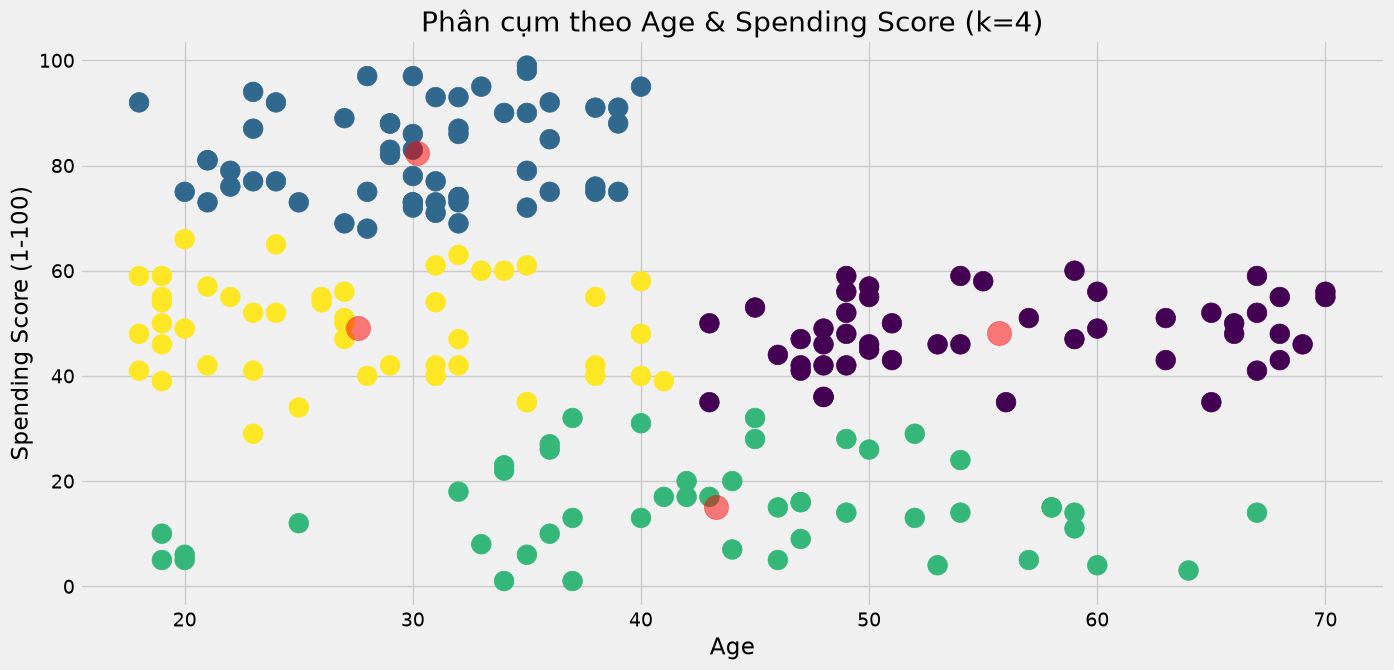

In [8]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
plt.figure(1, figsize=(15, 7))
plt.clf()
plt.scatter(x="Age", y="Spending Score (1-100)", data=data, c=labels1, s=200)
plt.scatter(x=centroids1[:, 0], y=centroids1[:, 1], s=300, c="red", alpha=0.5)
plt.ylabel("Spending Score (1-100)"), plt.xlabel("Age")
plt.title("Phân cụm theo Age & Spending Score (k=4)")
plt.show()

## Câu 8) Đánh giá bằng Silhouette coefficient

In [9]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
print("Silhouette (Age, Spending Score):", round(metrics.silhouette_score(X1, labels1, metric="euclidean"), 4))

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
Silhouette (Age, Spending Score): 0.4997


## Câu 9.1) Gom cụm Thu nhập – Điểm mua sắm

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


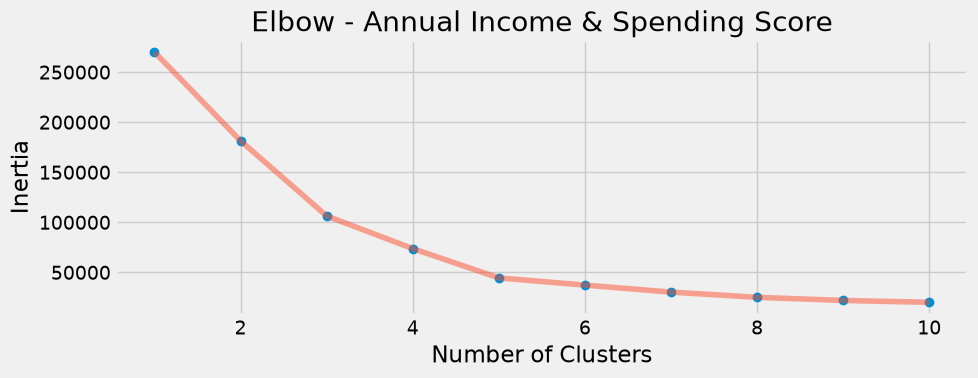

k =  1: inertia = 269,981.3
k =  2: inertia = 181,363.6
k =  3: inertia = 106,348.4
k =  4: inertia = 73,679.8
k =  5: inertia = 44,448.5
k =  6: inertia = 37,233.8
k =  7: inertia = 30,241.3
k =  8: inertia = 25,036.4
k =  9: inertia = 21,916.8
k = 10: inertia = 20,072.1


In [10]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
X2 = data[["Annual Income (k$)", "Spending Score (1-100)"]].iloc[:, :].values
inertia2 = elbow(X2, "Elbow - Annual Income & Spending Score")

**Chọn k:** Inertia giảm mạnh đến k = 5 (44 449), từ k = 6 trở đi mức giảm nhỏ dần (37 234, 30 241 …). Điểm khuỷu tay ở **k = 5**.

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
Số phần tử mỗi cụm: [81 39 22 35 23]
Tâm cụm (Income, Spending Score):
 [[55.3  49.52]
 [86.54 82.13]
 [25.73 79.36]
 [88.2  17.11]
 [26.3  20.91]]


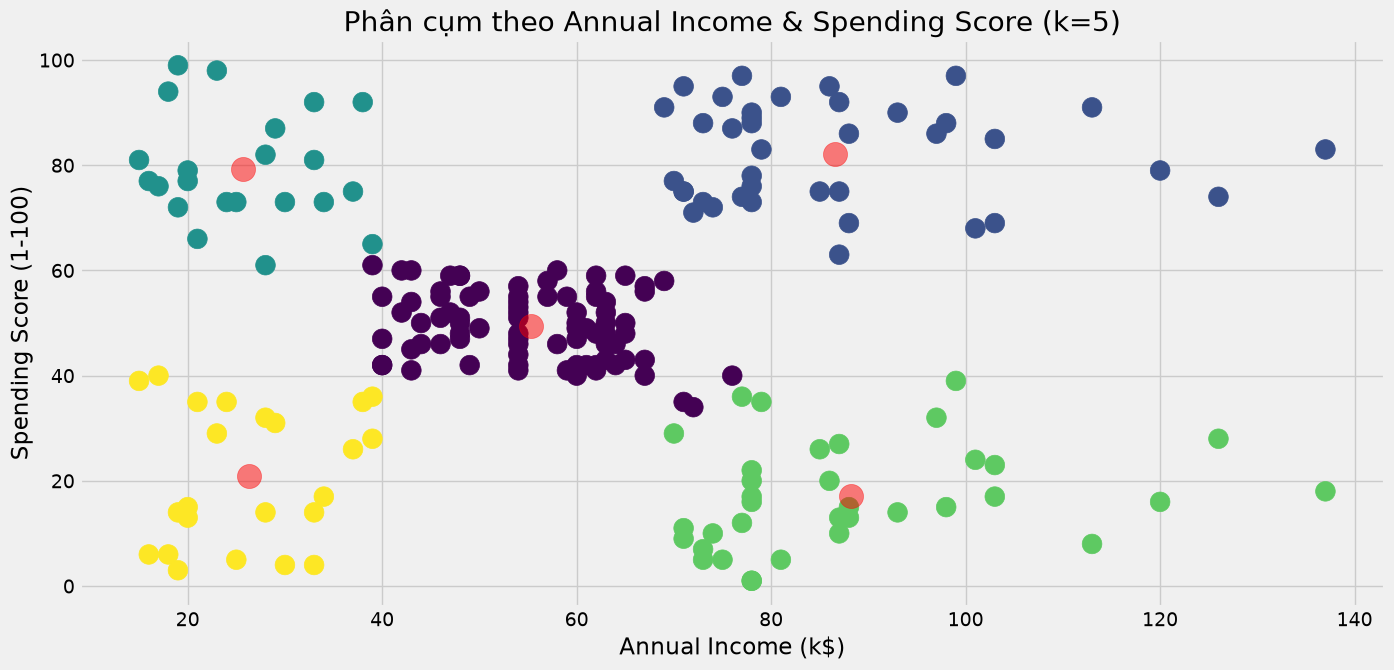

Silhouette (Income, Spending Score): 0.5539


In [11]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
algorithm = KMeans(n_clusters=5, init="k-means++", n_init=10, random_state=42)
algorithm.fit(X2)
labels2 = algorithm.labels_
centroids2 = algorithm.cluster_centers_
print("Số phần tử mỗi cụm:", np.bincount(labels2))
print("Tâm cụm (Income, Spending Score):\n", np.round(centroids2, 2))

plt.figure(1, figsize=(15, 7))
plt.clf()
plt.scatter(x="Annual Income (k$)", y="Spending Score (1-100)", data=data, c=labels2, s=200)
plt.scatter(x=centroids2[:, 0], y=centroids2[:, 1], s=300, c="red", alpha=0.5)
plt.ylabel("Spending Score (1-100)"), plt.xlabel("Annual Income (k$)")
plt.title("Phân cụm theo Annual Income & Spending Score (k=5)")
plt.show()
print("Silhouette (Income, Spending Score):", round(metrics.silhouette_score(X2, labels2, metric="euclidean"), 4))

## Câu 9.2) Gom cụm Tuổi – Thu nhập – Điểm mua sắm (3D)

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


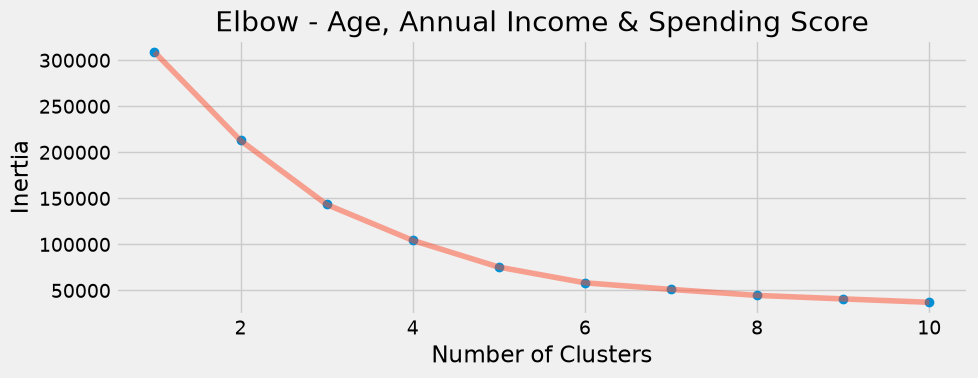

k =  1: inertia = 308,812.8
k =  2: inertia = 212,840.2
k =  3: inertia = 143,342.8
k =  4: inertia = 104,366.2
k =  5: inertia = 75,350.8
k =  6: inertia = 58,300.4
k =  7: inertia = 51,133.0
k =  8: inertia = 44,640.0
k =  9: inertia = 40,809.8
k = 10: inertia = 37,128.0


In [12]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
X3 = data[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].iloc[:, :].values
inertia3 = elbow(X3, "Elbow - Age, Annual Income & Spending Score")

**Chọn k:** Đường cong giảm đều hơn; mức giảm rõ cuối cùng là từ k = 5 (75 351) xuống k = 6 (58 300), sau đó chỉ còn giảm khoảng 7 000 mỗi bước. Chọn **k = 6**.

In [13]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
algorithm = KMeans(n_clusters=6, init="k-means++", n_init=10, random_state=42)
algorithm.fit(X3)
labels3 = algorithm.labels_
centroids3 = algorithm.cluster_centers_
print("Số phần tử mỗi cụm:", np.bincount(labels3))
print("Tâm cụm (Age, Income, Spending Score):\n", np.round(centroids3, 2))
print("Silhouette (Age, Income, Spending Score):", round(metrics.silhouette_score(X3, labels3, metric="euclidean"), 4))

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
Số phần tử mỗi cụm: [45 35 22 38 39 21]
Tâm cụm (Age, Income, Spending Score):
 [[56.16 53.38 49.09]
 [41.69 88.23 17.29]
 [25.27 25.73 79.36]
 [27.   56.66 49.13]
 [32.69 86.54 82.13]
 [44.14 25.14 19.52]]
Silhouette (Age, Income, Spending Score): 0.4523


In [14]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
data["label3"] = labels3
trace1 = go.Scatter3d(
    x=data["Age"], y=data["Spending Score (1-100)"], z=data["Annual Income (k$)"],
    mode="markers",
    marker=dict(color=data["label3"], size=10, line=dict(color=data["label3"], width=12), opacity=0.8),
)
layout = go.Layout(title="Clusters", scene=dict(
    xaxis=dict(title="Age"), yaxis=dict(title="Spending Score"), zaxis=dict(title="Annual Income")))
fig = go.Figure(data=[trace1], layout=layout)
fig.show()

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


Biểu đồ plotly ở trên có thể xoay tương tác khi mở notebook. Bản tĩnh bằng matplotlib để chèn vào báo cáo:

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


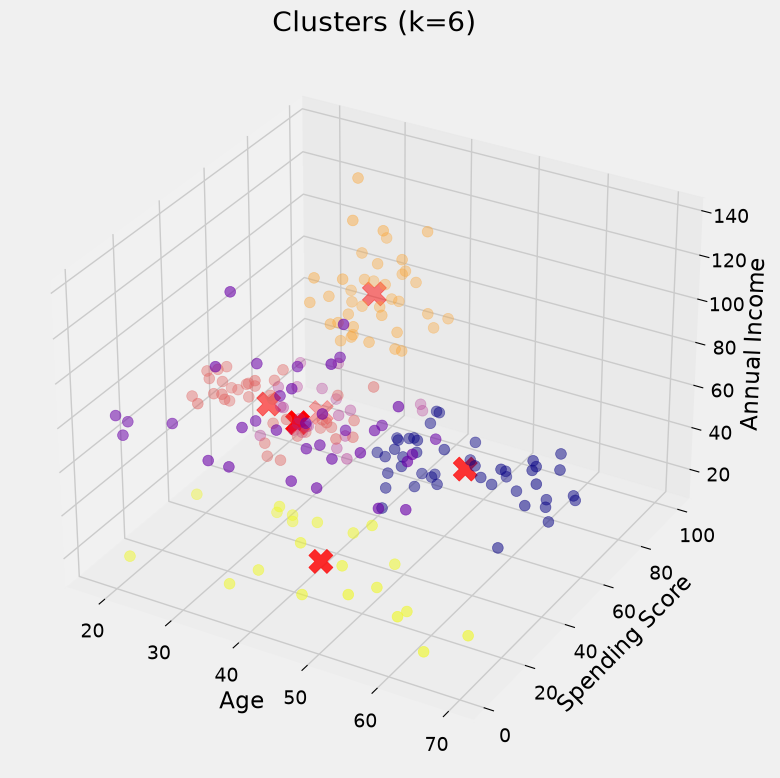

In [15]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection="3d")
sc = ax.scatter(data["Age"], data["Spending Score (1-100)"], data["Annual Income (k$)"],
                c=labels3, cmap="plasma", s=60, alpha=0.8)
ax.scatter(centroids3[:, 0], centroids3[:, 2], centroids3[:, 1], c="red", s=300, marker="X")
ax.set_xlabel("Age"); ax.set_ylabel("Spending Score"); ax.set_zlabel("Annual Income")
ax.set_title("Clusters (k=6)")
plt.tight_layout(); plt.show()

**Nhận xét:**

- Silhouette: (Tuổi, Điểm mua sắm) k = 4 → 0.4997; (Thu nhập, Điểm mua sắm) k = 5 → **0.5539** (tốt nhất); (Tuổi, Thu nhập, Điểm mua sắm) k = 6 → 0.4523.
- Cặp Thu nhập – Điểm mua sắm cho các cụm tách biệt rõ nhất, gồm 5 nhóm khách hàng dễ diễn giải: thu nhập cao – chi tiêu cao (~86k$, điểm 82), thu nhập cao – chi tiêu thấp (~88k$, điểm 17), thu nhập thấp – chi tiêu cao (~26k$, điểm 79), thu nhập thấp – chi tiêu thấp (~26k$, điểm 21) và nhóm trung bình (~55k$, điểm 50).
- Cặp Tuổi – Điểm mua sắm cho thấy khách hàng trẻ (khoảng 30 tuổi) có xu hướng chi tiêu nhiều, còn nhóm trên 40 tuổi phần lớn chi tiêu ở mức thấp hoặc trung bình.
- Gom cụm 3 thuộc tính chia nhỏ hơn (6 nhóm) nhưng silhouette thấp hơn, do thêm chiều Tuổi làm các cụm chồng lấn nhiều hơn.